<a href="https://colab.research.google.com/github/MohammedHany123/akt26_gpu_dev/blob/main/L2_Air_Quality_AI_Methods_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
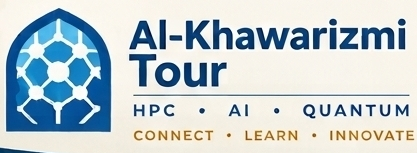
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 2 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Introduction to AI Methods — Beijing Air Quality · Hands-on &amp; Week-2 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos of supervised, unsupervised and neural-network methods (slide references in each heading) · Part B: the week-long <b>AI Methods Shoot-out</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A8) | during the 2-hour lecture | one demo per family of methods, all on the same data |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells and write the model card with your conclusions |

**Input:** your cleaned Week-1 training years `beijing_clean_team<N>.csv.gz`. If it is not found, the raw UCI training years are used (real gaps only). The **test year** (1 Mar 2016 – 28 Feb 2017) always comes from the untouched UCI data.

**Running tasks**
* **Virtual PM2.5 sensor** — regression of PM2.5 from gases, weather, time and station (no PM10).
* **Unhealthy-hour alert** — classify PM2.5 > 75 µg/m³.
* **Pollution regimes** — clustering of daily 24-hour PM2.5 profiles.
* **24-hour-ahead forecast** — PM2.5 at *t* + 24 h from the past.

**Speed:** `STEP = 3` keeps every 3rd hour for the demos (≈ 100k rows). Set `STEP = 1` for final results on a fast machine / HPC node.

## 0 · Setup

In [ ]:
TEAM_ID = 1135
SEED = 2000 + TEAM_ID
STEP = 3                      # use every STEP-th hour in demos (1 = all data)

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, cross_val_score
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
import sklearn; print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


---
# Part A · Guided demos
## A1 · Data, features and the time split  *(slides 2 & 6)*

In [ ]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
SPLIT = pd.Timestamp("2016-03-01")
test_year = raw[raw["datetime"] >= SPLIT].drop(columns=["datetime"])

fname = f"beijing_clean_team{TEAM_ID}.csv.gz"
if os.path.exists(fname):
    train_years = pd.read_csv(fname); print("Using your Week-1 cleaned data:", train_years.shape)
else:
    train_years = raw[raw["datetime"] < SPLIT].drop(columns=["datetime"]); print("Week-1 file not found -> raw UCI training years")

train = add_features(train_years).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
test = add_features(test_year).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
FEATS = NUM_FEATS + CAT_FEATS
X, y = train[FEATS], train[TARGET]
Xs, ys = X.iloc[::STEP], y.iloc[::STEP]            # time order is preserved
print(f"train {len(train):,} rows (demo subset {len(Xs):,}) | test year {len(test):,} rows")

def pipe(model, scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)),
                     ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)                   # SAME folds for every model

Loaded 420,768 rows x 18 columns from UCI download
Week-1 file not found -> raw UCI training years
train 309,276 rows (demo subset 103,092) | test year 102,753 rows


## A2 · Virtual PM2.5 sensor — the model zoo  *(slides 10–17)*
Slow methods (k-NN, kernel SVR, MLP) are trained on a further subsample — an HPC trade-off you will revisit in the bonus.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

zoo = {  # name: (model, extra thinning factor for slow methods)
    "Dummy (mean)":      (DummyRegressor(), 1),
    "Linear":            (LinearRegression(), 1),
    "Ridge":             (Ridge(alpha=1.0), 1),
    "Lasso":             (Lasso(alpha=0.1, max_iter=5000), 1),
    "kNN (k=15)":        (KNeighborsRegressor(n_neighbors=15, weights="distance"), 4),
    "SVR (RBF)":         (SVR(C=30, epsilon=5), 12),
    "Decision tree":     (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0), 1),
    "Random forest":     (RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
    "Gradient boosting": (HistGradientBoostingRegressor(max_iter=300, random_state=0), 1),
    "MLP (64-32)":       (MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=0), 2),
}
rows = []
for name, (m, thin) in zoo.items():
    Xa, ya = Xs.iloc[::thin], ys.iloc[::thin]
    t0 = time.perf_counter()
    r = cross_validate(pipe(m), Xa, ya, cv=tscv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"model": name, "rows": len(Xa), "RMSE": -r["test_rmse"].mean(), "RMSE sd": r["test_rmse"].std(),
                 "MAE": -r["test_mae"].mean(), "R2": r["test_r2"].mean(), "seconds": time.perf_counter() - t0})
board = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
board.round(2)

,model,rows,RMSE,RMSE sd,MAE,R2,seconds
0,MLP (64-32),51546,42.65,9.10,27.64,0.70,63.67
1,Random forest,103092,42.93,7.53,25.70,0.69,98.60
2,Gradient boosting,103092,43.19,10.92,26.23,0.69,13.85
3,Lasso,103092,46.63,6.83,31.65,0.63,9.14
4,Ridge,103092,46.67,6.87,31.85,0.63,0.90
5,Linear,103092,46.71,6.87,31.87,0.63,1.17
6,kNN (k=15),25773,48.20,6.43,30.91,0.60,1.94
7,SVR (RBF),8591,48.48,14.24,28.72,0.63,6.67
8,Decision tree,103092,49.71,9.37,30.48,0.59,2.49
9,Dummy (mean),103092,80.91,17.58,61.71,-0.04,4.32


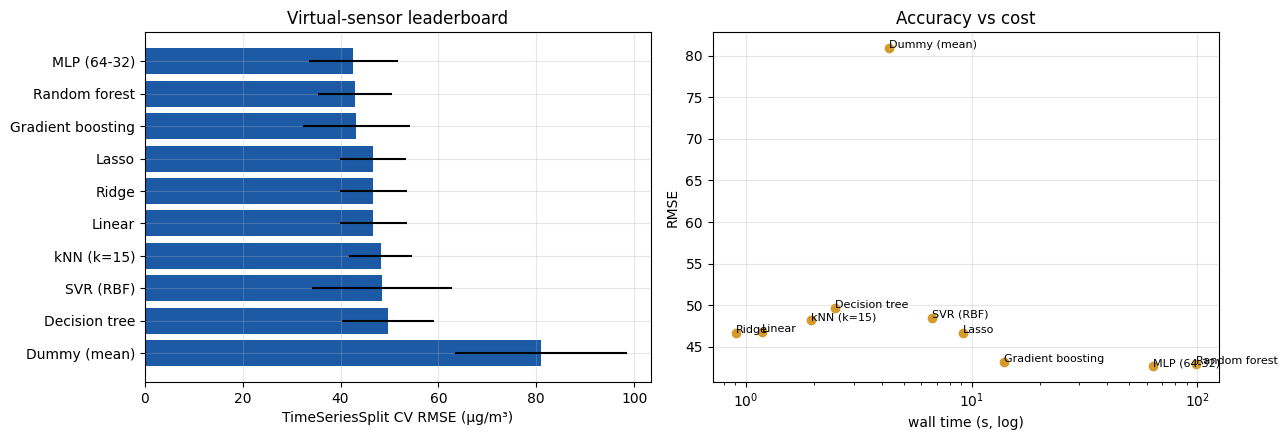

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(board["model"], board["RMSE"], xerr=board["RMSE sd"], color="#1c5aa6"); ax[0].invert_yaxis()
ax[0].set_xlabel("TimeSeriesSplit CV RMSE (µg/m³)"); ax[0].set_title("Virtual-sensor leaderboard")
ax[1].scatter(board["seconds"], board["RMSE"], color="#d49a2a")
for _, r_ in board.iterrows(): ax[1].annotate(r_["model"], (r_["seconds"], r_["RMSE"]), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("wall time (s, log)"); ax[1].set_ylabel("RMSE"); ax[1].set_title("Accuracy vs cost")
plt.tight_layout(); plt.show()

## A3 · Bias–variance in one picture  *(slide 7)*

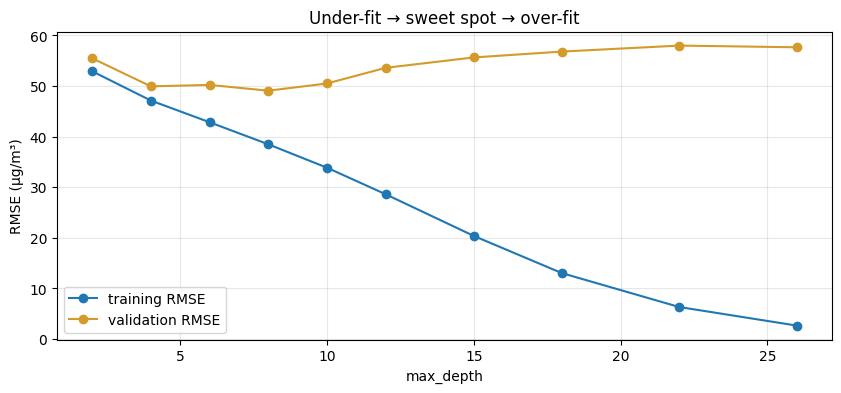

In [ ]:
from sklearn.model_selection import validation_curve
depths = [2, 4, 6, 8, 10, 12, 15, 18, 22, 26]
tr, va = validation_curve(pipe(DecisionTreeRegressor(random_state=0), scale=False), Xs, ys, param_name="model__max_depth",
                          param_range=depths, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
plt.plot(depths, -tr.mean(1), "o-", label="training RMSE"); plt.plot(depths, -va.mean(1), "o-", color="#d49a2a", label="validation RMSE")
plt.xlabel("max_depth"); plt.ylabel("RMSE (µg/m³)"); plt.legend(); plt.title("Under-fit → sweet spot → over-fit"); plt.show()

## A4 · Unhealthy-hour alert  *(slides 8, 10, 16)*
Label: **1 if PM2.5 > 75 µg/m³**. ROC curves use a time-based validation block (the last training year).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

THR = 75
yc_s = (ys > THR).astype(int)
print(f"share of unhealthy hours in training data: {yc_s.mean():.1%}")
clfs = {"Logistic": (LogisticRegression(max_iter=2000), 1), "Gaussian NB": (GaussianNB(), 1),
        "kNN (k=25)": (KNeighborsClassifier(n_neighbors=25), 4),
        "Random forest": (RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
        "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, random_state=0), 1)}
rows = []
for name, (m, thin) in clfs.items():
    r = cross_validate(pipe(m), Xs.iloc[::thin], yc_s.iloc[::thin], cv=tscv, n_jobs=-1,
                       scoring=["precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)

share of unhealthy hours in training data: 39.7%


,model,precision,recall,f1,roc_auc
0,Logistic,0.865,0.793,0.827,0.945
4,Gradient boosting,0.870,0.750,0.797,0.945
3,Random forest,0.850,0.803,0.825,0.944
2,kNN (k=25),0.826,0.696,0.752,0.907
1,Gaussian NB,0.770,0.689,0.712,0.880


In [ ]:
VAL = pd.Timestamp("2015-03-01")
tr_m = (train["datetime"] < VAL).values[::STEP]; va_m = ~tr_m
plt.figure(figsize=(5.5, 5))
for name in ["Logistic", "Gaussian NB", "Gradient boosting"]:
    p = pipe(clfs[name][0]).fit(Xs[tr_m], yc_s[tr_m]).predict_proba(Xs[va_m])[:, 1]
    fpr, tpr, _ = roc_curve(yc_s[va_m], p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_s[va_m], p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("false-alarm rate"); plt.ylabel("recall (unhealthy hours caught)")
plt.legend(); plt.title("ROC — validation year Mar 2015 – Feb 2016"); plt.show()

## A5 · Pollution regimes — clustering daily profiles  *(slides 19–21)*

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

day = train.assign(date=train["datetime"].dt.date)
prof = day.pivot_table(index=["station", "date"], columns="hour", values=TARGET).dropna()     # complete 24-h days
level = np.log1p(prof.mean(axis=1))                                                           # how polluted
shape = prof.div(prof.mean(axis=1), axis=0)                                                   # when in the day
Z = np.column_stack([StandardScaler().fit_transform(level.values[:, None]) * 2, StandardScaler().fit_transform(shape)])
print(f"{len(prof):,} station-days x 24 hours")

pca = PCA(n_components=6).fit(Z)
print("explained variance (first 6 PCs):", pca.explained_variance_ratio_.round(3))
ks = range(2, 9); sil, dbi, inertia = [], [], []
samp = rng.choice(len(Z), min(6000, len(Z)), replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[samp], km.labels_[samp])); dbi.append(davies_bouldin_score(Z, km.labels_))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow"); ax[1].plot(ks, sil, "o-", color="#0f7a4d"); ax[1].set_title("Silhouette ↑")
ax[2].plot(ks, dbi, "o-", color="#b8350f"); ax[2].set_title("Davies–Bouldin ↓")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

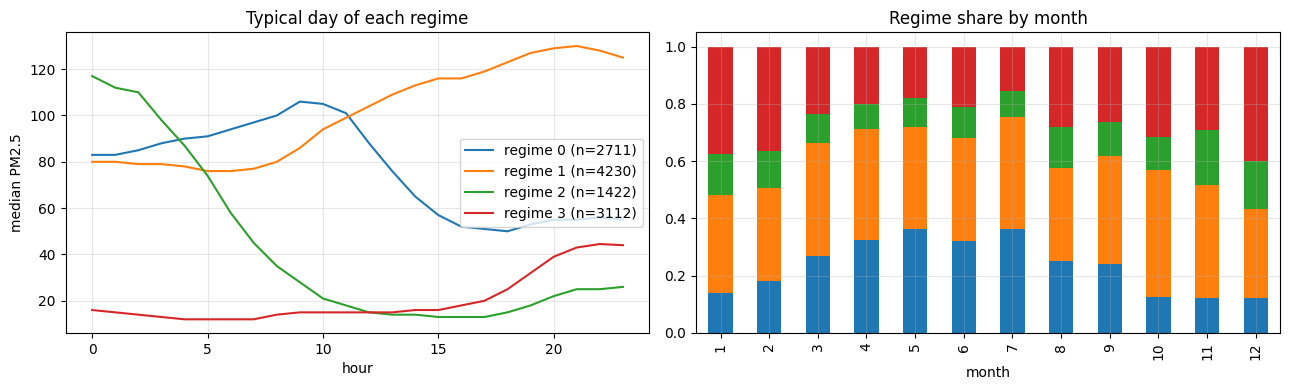

In [ ]:
K = 4                                                   # choose from the plots above
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
lab = pd.Series(km.labels_, index=prof.index, name="regime")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in range(K):
    ax[0].plot(range(24), prof[lab.values == k].median(), label=f"regime {k} (n={int((lab == k).sum())})")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("median PM2.5"); ax[0].legend(); ax[0].set_title("Typical day of each regime")
months = pd.to_datetime(pd.Series(prof.index.get_level_values("date"))).dt.month.values
pd.crosstab(months, lab.values, normalize="index").plot.bar(stacked=True, ax=ax[1], legend=False)
ax[1].set_xlabel("month"); ax[1].set_title("Regime share by month"); plt.tight_layout(); plt.show()

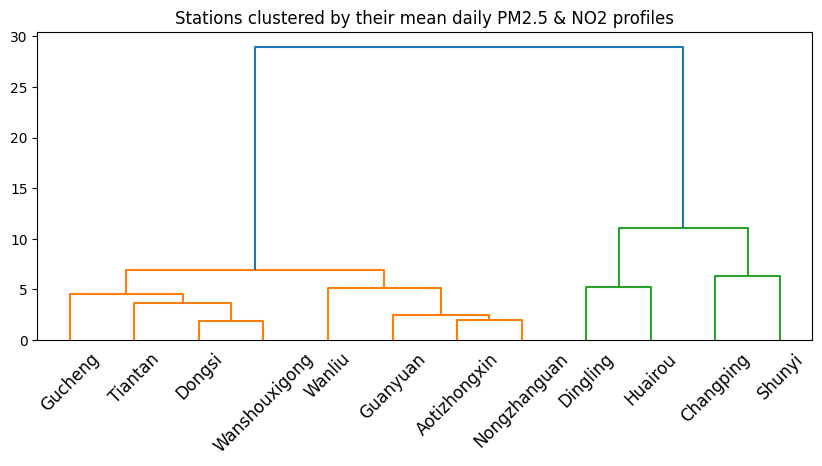

DBSCAN noise days: 44 -> most frequent dates:
2016-02-08    8
2015-11-30    6
2014-01-30    3
2014-05-27    3
2015-12-25    2
2015-02-18    2
2014-03-05    2
2015-06-07    1
Name: count, dtype: int64


In [ ]:
# Which stations behave alike? hierarchical clustering of the 12 mean diurnal profiles (PM2.5 + NO2)
from scipy.cluster.hierarchy import linkage, dendrogram
sig = train.groupby(["station", "hour"])[["PM2.5", "NO2"]].mean().unstack("hour")
dendrogram(linkage(StandardScaler().fit_transform(sig), method="ward"), labels=sig.index.tolist(), leaf_rotation=45)
plt.title("Stations clustered by their mean daily PM2.5 & NO2 profiles"); plt.grid(False); plt.show()

# Anomalous days: DBSCAN noise points among daily vectors
from sklearn.neighbors import NearestNeighbors
P = pca.transform(Z)[:, :3]
kdist = NearestNeighbors(n_neighbors=15).fit(P).kneighbors(P)[0][:, -1]
db = DBSCAN(eps=float(np.quantile(kdist, 0.98)), min_samples=15).fit(P)      # eps from the k-distance curve
noise = prof.index[db.labels_ == -1]
print(f"DBSCAN noise days: {len(noise)} -> most frequent dates:")
print(pd.Series([d for _, d in noise]).value_counts().head(8))

## A6 · A neuron from scratch (NumPy)  *(slides 24 & 26)*

single linear neuron on log(PM2.5): training RMSE = 109.1 µg/m³


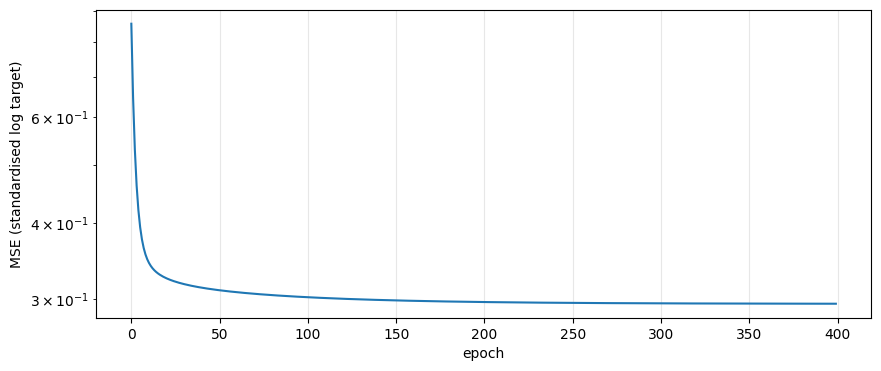

In [ ]:
prep = pipe(DummyRegressor()).named_steps["prep"].fit(Xs)
Xn = prep.transform(Xs); t = np.log1p(ys.values); tm, tsd = t.mean(), t.std(); tt = (t - tm) / tsd
w = rng.normal(0, .05, Xn.shape[1]); b = 0.0; lr = 0.05; hist = []
for epoch in range(400):
    yh = Xn @ w + b                           # forward
    err = yh - tt; hist.append(np.mean(err ** 2))
    w -= lr * 2 * Xn.T @ err / len(tt)        # back-propagation + gradient step
    b -= lr * 2 * err.mean()
pred = np.expm1(( Xn @ w + b) * tsd + tm)
print(f"single linear neuron on log(PM2.5): training RMSE = {np.sqrt(np.mean((pred - ys.values) ** 2)):.1f} µg/m³")
plt.plot(hist); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised log target)"); plt.show()

## A7 · Hyper-parameter search — and why it loves HPC  *(slide 29)*

In [ ]:
import os
from sklearn.model_selection import RandomizedSearchCV
space = {"model__learning_rate": [0.03, 0.06, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63, 127],
         "model__min_samples_leaf": [20, 50, 100], "model__l2_regularization": [0.0, 0.1, 1.0]}
for jobs in [1, -1]:
    t0 = time.perf_counter()
    s = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(max_iter=200, random_state=0), scale=False), space, n_iter=8,
                           cv=TimeSeriesSplit(3), scoring="neg_root_mean_squared_error", random_state=0, n_jobs=jobs).fit(Xs, ys)
    print(f"n_jobs={jobs:>2}: {time.perf_counter() - t0:6.1f} s | best CV RMSE {-s.best_score_:.2f}")
print("cores available:", os.cpu_count(), "| note: HistGradientBoosting itself is multi-threaded (OpenMP)")

## A8 · 24-hour-ahead forecast with lag features  *(slide 28)*

In [ ]:
def forecast_frame(d, horizon=24):
    """Per station: regular hourly index, backward-looking lags, target = PM2.5 at t + horizon."""
    out = []
    for st, g in d.groupby("station"):
        g = g.set_index("datetime").sort_index()
        g = g[~g.index.duplicated()].asfreq("h")
        f = pd.DataFrame(index=g.index)
        for L in [0, 1, 2, 3, 6, 12, 24, 48]:
            f[f"pm_lag{L}"] = g[TARGET].shift(L)
        f["pm_roll24"] = g[TARGET].rolling(24, min_periods=12).mean()
        for c in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            f[c] = g[c]
        tgt_time = f.index + pd.Timedelta(hours=horizon)
        f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * tgt_time.hour / 24), np.cos(2 * np.pi * tgt_time.hour / 24)
        f["month_sin"], f["month_cos"] = np.sin(2 * np.pi * tgt_time.month / 12), np.cos(2 * np.pi * tgt_time.month / 12)
        f["y"] = g[TARGET].shift(-horizon); f["station"] = st
        out.append(f.reset_index())
    return pd.concat(out, ignore_index=True).dropna(subset=["y", "pm_lag0"]).sort_values("datetime")

fc = forecast_frame(train)
fX = fc.drop(columns=["y", "datetime", "station"]); fy = fc["y"]
va = (fc["datetime"] >= VAL).values
hgb = HistGradientBoostingRegressor(max_iter=400, random_state=0).fit(fX[~va], fy[~va])
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(f"validation year | persistence (tomorrow = today) RMSE = {rmse(fy[va], fX.loc[va, 'pm_lag0']):.1f}"
      f" | gradient boosting on lags RMSE = {rmse(fy[va], hgb.predict(fX[va])):.1f} µg/m³")

---
# Part B · Week-2 Team Challenge — *The AI Methods Shoot-out*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The environmental agency will deploy <b>one</b> model to (a) estimate PM2.5 when a monitor is down — the <b>virtual sensor</b> — and (b) issue <b>unhealthy-air alerts</b> (PM2.5 &gt; 75 µg/m³). Management asks: <i>which AI method, and why should we trust it?</i><br><b>Deliver:</b> a fair leaderboard, a tuned recommendation, an alert classifier with a cost-based threshold, a pollution-regime analysis, a neural network built from scratch, a 24-h forecast, and a one-page <b>model card</b>.</div>

| # | Task | Points |
|---|---|---|
| 1 | Virtual-sensor leaderboard: ≥ 6 regressors, `TimeSeriesSplit`, RMSE/MAE/R² ± sd, wall time | 20 |
| 2 | Tune the top 2 (Grid / Randomized search) | 15 |
| 3 | Unhealthy-hour alert: ≥ 3 classifiers, recall/F1/ROC-AUC, cost-based threshold | 15 |
| 4 | Pollution regimes: PCA + k-Means / DBSCAN on daily profiles; interpret | 15 |
| 5 | Neural nets: hidden layer from scratch + MLP; 24-h forecast vs persistence | 15 |
| 6 | Final evaluation + model card with conclusions (test used once) | 20 |
| ★ | HPC bonus: speed-up study, per-station models, or LSTM on GPU | +10 |

**Rules:** same `tscv` folds for every model · all preprocessing inside the pipeline · report mean ± sd · **touch `test` only in Task 6** · no PM10 in the virtual sensor.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–4 · Day 5 Task 5 (+ bonus) · Days 6–7 Task 6 (model card & conclusions).

## Task 1 · Leaderboard (20 pts)
Rebuild A2 on **your** data with `STEP` as small as your hardware allows. Add at least one model not in the zoo (e.g. `ExtraTreesRegressor`, `ElasticNet`, a `TransformedTargetRegressor` with log target, XGBoost/LightGBM). Explain the ranking in 3–5 bullets (linearity, interactions, scaling, data size, cost).

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

In [ ]:
import os
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    f1_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("default")

print("Environment ready.")

In [ ]:
from pathlib import Path

filename = "beijing_clean_team1135.csv.gz"
matches = list(Path("/content/drive/MyDrive").rglob(filename))

if not matches:
    raise FileNotFoundError(
        f"Could not find {filename} in MyDrive. "
        "Check which Drive folder contains it."
    )

DATA_PATH = str(matches[0])
print("Dataset found:", DATA_PATH)

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(DATA_PATH, compression="gzip")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst five rows:")
display(df.head())

print("\nMissing values per column:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

print("\nDuplicate rows:", df.duplicated().sum())

In [ ]:
# Inspect likely timestamp and station fields before choosing them.
for col in df.columns:
    name = col.lower()
    if any(term in name for term in ["date", "time", "station", "site", "pm25", "pm2.5", "pm10"]):
        print(f"{col}:")
        print(df[col].head(3).tolist())
        print()

In [ ]:
df["timestamp"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

assert df["timestamp"].notna().all(), "Some timestamps could not be parsed."

df = df.sort_values(
    ["timestamp", "station"]
).reset_index(drop=True)

print("Number of stations:", df["station"].nunique())
print("\nRows per station:")
display(df.groupby("station").size().sort_values(ascending=False).to_frame("rows"))

print("\nDate range:")
print("Start:", df["timestamp"].min())
print("End:  ", df["timestamp"].max())

print("\nMissing PM2.5 targets:", df["PM2.5"].isna().sum())

# A timestamp may appear once per station, but should not repeat
# within the same station.
duplicate_station_hours = df.duplicated(
    subset=["station", "timestamp"]
).sum()

print("Duplicate station-hour records:", duplicate_station_hours)
assert duplicate_station_hours == 0, "Resolve duplicate station-hour records first."

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

unique_times = np.sort(df["timestamp"].unique())
cut_position = int(len(unique_times) * 0.80)
cut_position = min(max(cut_position, 1), len(unique_times) - 1)

cutoff_time = pd.Timestamp(unique_times[cut_position])

dev_df = df.loc[df["timestamp"] < cutoff_time].copy().reset_index(drop=True)
test_df = df.loc[df["timestamp"] >= cutoff_time].copy().reset_index(drop=True)

print("Development rows:", len(dev_df))
print("Development period:", dev_df["timestamp"].min(), "to", dev_df["timestamp"].max())
print("\nFinal holdout created. Do not evaluate it until Task 6.")

In [ ]:
N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

dev_times = np.sort(dev_df["timestamp"].unique())
dev_time_values = dev_df["timestamp"].to_numpy()

cv_folds = []

for fold, (train_time_idx, valid_time_idx) in enumerate(
    tscv.split(dev_times), start=1
):
    train_times = dev_times[train_time_idx]
    valid_times = dev_times[valid_time_idx]

    train_idx = np.flatnonzero(np.isin(dev_time_values, train_times))
    valid_idx = np.flatnonzero(np.isin(dev_time_values, valid_times))

    # A fold must be strictly chronological.
    assert (
        dev_df.iloc[train_idx]["timestamp"].max()
        < dev_df.iloc[valid_idx]["timestamp"].min()
    )

    cv_folds.append((train_idx, valid_idx))

    print(
        f"Fold {fold}: "
        f"train={len(train_idx):,} rows, "
        f"validation={len(valid_idx):,} rows | "
        f"validation starts {dev_df.iloc[valid_idx]['timestamp'].min()}"
    )

print("\nAll models must use these same cv_folds.")

In [ ]:
def add_time_features(data):
    data = data.copy()

    data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
    data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
    data["month_sin"] = np.sin(2 * np.pi * (data["month"] - 1) / 12)
    data["month_cos"] = np.cos(2 * np.pi * (data["month"] - 1) / 12)

    data["day_of_week"] = data["timestamp"].dt.dayofweek

    return data

dev_features = add_time_features(dev_df)

target_col = "PM2.5"

# Explicitly exclude PM10, row number, raw timestamp, and the target.
# station_canon is redundant with station in this dataset, so use station only.
excluded_cols = {
    "PM2.5", "PM10", "No", "timestamp",
    "year", "month", "day", "hour", "station_canon"
}

feature_cols = [
    col for col in dev_features.columns
    if col not in excluded_cols
]

# Keep only rows with an observed target for supervised regression.
valid_target_mask = dev_features[target_col].notna()

reg_df = (
    dev_features.loc[valid_target_mask]
    .copy()
    .reset_index(drop=True)
)

X = reg_df[feature_cols].copy()
y = reg_df[target_col].copy()

# Use categorical encoders for these columns.
categorical_features = ["station", "wd"]
numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]

print("Feature columns:", feature_cols)
print("\nPM10 included?", "PM10" in feature_cols)
print("Regression rows with known PM2.5:", len(reg_df))
print("Rows excluded due to missing PM2.5:", int((~valid_target_mask).sum()))
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

assert "PM10" not in feature_cols
assert "PM2.5" not in feature_cols

In [ ]:
reg_times = reg_df["timestamp"].to_numpy()
unique_reg_times = np.sort(reg_df["timestamp"].unique())

cv_folds = []

for train_time_idx, valid_time_idx in TimeSeriesSplit(
    n_splits=N_SPLITS
).split(unique_reg_times):
    train_times = unique_reg_times[train_time_idx]
    valid_times = unique_reg_times[valid_time_idx]

    train_idx = np.flatnonzero(np.isin(reg_times, train_times))
    valid_idx = np.flatnonzero(np.isin(reg_times, valid_times))

    assert reg_df.iloc[train_idx]["timestamp"].max() < (
        reg_df.iloc[valid_idx]["timestamp"].min()
    )

    cv_folds.append((train_idx, valid_idx))

print("Rebuilt", len(cv_folds), "chronological folds for the regression dataset.")

In [ ]:
import time
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("scikit-learn version:", sklearn.__version__)
print("STEP:", STEP)

In [ ]:
all_dev_times = np.sort(reg_df["timestamp"].unique())
selected_times = all_dev_times[::STEP]

experiment_df = (
    reg_df[reg_df["timestamp"].isin(selected_times)]
    .copy()
    .sort_values(["timestamp", "station"])
    .reset_index(drop=True)
)

X_exp = experiment_df[feature_cols].copy()
y_exp = experiment_df[target_col].copy()
time_exp = experiment_df["timestamp"].to_numpy()

# Create folds on unique timestamps, then map them back to row indices.
unique_exp_times = np.sort(experiment_df["timestamp"].unique())
cv_folds = []

for train_time_idx, valid_time_idx in TimeSeriesSplit(n_splits=5).split(unique_exp_times):
    train_times = unique_exp_times[train_time_idx]
    valid_times = unique_exp_times[valid_time_idx]

    train_idx = np.flatnonzero(np.isin(time_exp, train_times))
    valid_idx = np.flatnonzero(np.isin(time_exp, valid_times))

    assert experiment_df.iloc[train_idx]["timestamp"].max() < (
        experiment_df.iloc[valid_idx]["timestamp"].min()
    )

    cv_folds.append((train_idx, valid_idx))

print(f"Rows in experiment: {len(experiment_df):,}")
print(f"Unique timestamps: {len(unique_exp_times):,}")
print(f"Features: {X_exp.shape[1]}")
print(f"Shared CV folds: {len(cv_folds)}")
print("PM10 in features:", "PM10" in X_exp.columns)

assert "PM10" not in X_exp.columns

In [ ]:
numeric_features = [
    col for col in feature_cols if col not in categorical_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

models = {
    "Dummy mean baseline": DummyRegressor(strategy="mean"),

    "Ridge": Ridge(alpha=10.0),

    "ElasticNet": ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=3000,
        random_state=SEED
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_leaf=5,
        random_state=SEED
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=SEED
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=SEED
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=SEED
    )
}

print(f"Configured {len(models)} regressors, including the baseline.")

In [ ]:

results = []

for model_name, estimator in models.items():
    print(f"Running: {model_name}")
    fold_metrics = []
    start = time.perf_counter()

    for fold_number, (train_idx, valid_idx) in enumerate(cv_folds, start=1):
        X_train = X_exp.iloc[train_idx]
        y_train = y_exp.iloc[train_idx]
        X_valid = X_exp.iloc[valid_idx]
        y_valid = y_exp.iloc[valid_idx]

        pipeline = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("model", clone(estimator))
        ])

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_valid)

        fold_metrics.append({
            "fold": fold_number,
            "RMSE": np.sqrt(mean_squared_error(y_valid, predictions)),
            "MAE": mean_absolute_error(y_valid, predictions),
            "R2": r2_score(y_valid, predictions)
        })

    elapsed = time.perf_counter() - start
    fold_df = pd.DataFrame(fold_metrics)

    results.append({
        "Model": model_name,
        "RMSE mean": fold_df["RMSE"].mean(),
        "RMSE std": fold_df["RMSE"].std(ddof=1),
        "MAE mean": fold_df["MAE"].mean(),
        "MAE std": fold_df["MAE"].std(ddof=1),
        "R2 mean": fold_df["R2"].mean(),
        "R2 std": fold_df["R2"].std(ddof=1),
        "Runtime seconds": elapsed,
        "Fold results": fold_metrics
    })

    print(
        f"  RMSE = {fold_df['RMSE'].mean():.3f} "
        f"± {fold_df['RMSE'].std(ddof=1):.3f} | "
        f"time = {elapsed:.1f}s"
    )

leaderboard = (
    pd.DataFrame(results)
    .sort_values("RMSE mean")
    .reset_index(drop=True)
)

display(
    leaderboard.drop(columns="Fold results").round(4)
)

In [ ]:
best_model = leaderboard.iloc[0]
fastest_model = leaderboard.loc[leaderboard["Runtime seconds"].idxmin()]

print(
    f"Lowest mean validation RMSE: {best_model['Model']} "
    f"({best_model['RMSE mean']:.3f} ± {best_model['RMSE std']:.3f})"
)
print(
    f"Fastest model: {fastest_model['Model']} "
    f"({fastest_model['Runtime seconds']:.1f} seconds)"
)

print("\nInterpretation prompts:")
print("1. Compare the strongest nonlinear models with Ridge and ElasticNet.")
print("2. Check whether lower RMSE also comes with lower MAE.")
print("3. Compare each model's fold-to-fold variability.")
print("4. Consider whether the accuracy gain justifies the extra runtime.")
print("5. Compare every learned model against the Dummy mean baseline.")

## Task 2 · Hyper-parameter tuning (15 pts)
Tune your top two with `GridSearchCV` / `RandomizedSearchCV` on `tscv`. Report best parameters, CV RMSE before → after, search time. Is the gain larger than the fold standard deviation?

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import randint

# Tune the existing preprocessing + model pipelines.
hgb_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", HistGradientBoostingRegressor(random_state=SEED))
])

extra_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        n_estimators=100,
        n_jobs=-1,
        random_state=SEED
    ))
])

hgb_param_grid = {
    "model__learning_rate": [0.05, 0.08, 0.1],
    "model__max_iter": [100, 150],
    "model__max_leaf_nodes": [15, 31],
    "model__l2_regularization": [0.0, 1.0]
}

extra_param_distributions = {
    "model__n_estimators": [80, 120, 160],
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_leaf": [2, 4, 8],
    "model__max_features": [0.7, 1.0]
}

print("Hist Gradient Boosting grid combinations:",
      np.prod([len(v) for v in hgb_param_grid.values()]))
print("Extra Trees randomized search candidates: 12")

In [ ]:
hgb_search = GridSearchCV(
    estimator=hgb_pipeline,
    param_grid=hgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=False
)

start = time.perf_counter()
hgb_search.fit(X_exp, y_exp)
hgb_search_seconds = time.perf_counter() - start

hgb_best_rmse = -hgb_search.best_score_

print("Best parameters:")
print(hgb_search.best_params_)
print(f"Best CV RMSE: {hgb_best_rmse:.4f}")
print(f"Search time: {hgb_search_seconds:.1f} seconds")

In [ ]:
extra_search = RandomizedSearchCV(
    estimator=extra_pipeline,
    param_distributions=extra_param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    n_jobs=1,
    random_state=SEED,
    verbose=1,
    refit=True,
    return_train_score=False
)

start = time.perf_counter()
extra_search.fit(X_exp, y_exp)
extra_search_seconds = time.perf_counter() - start

extra_best_rmse = -extra_search.best_score_

print("Best parameters:")
print(extra_search.best_params_)
print(f"Best CV RMSE: {extra_best_rmse:.4f}")
print(f"Search time: {extra_search_seconds:.1f} seconds")

Fitting 5 folds for each of 12 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Best parameters:
{'model__n_estimators': 120, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': 35}
Best CV RMSE: 41.6996
Search time: 903.9 seconds


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
baseline_by_model = {
    row["Model"]: row["RMSE mean"]
    for _, row in leaderboard.iterrows()
}

comparison = pd.DataFrame([
    {
        "Model": "Hist Gradient Boosting",
        "Before RMSE": baseline_by_model["Hist Gradient Boosting"],
        "After RMSE": hgb_best_rmse,
        "Search time (s)": hgb_search_seconds,
        "Original fold RMSE std": float(
            leaderboard.loc[
                leaderboard["Model"] == "Hist Gradient Boosting",
                "RMSE std"
            ].iloc[0]
        )
    },
    {
        "Model": "Extra Trees",
        "Before RMSE": baseline_by_model["Extra Trees"],
        "After RMSE": extra_best_rmse,
        "Search time (s)": extra_search_seconds,
        "Original fold RMSE std": float(
            leaderboard.loc[
                leaderboard["Model"] == "Extra Trees",
                "RMSE std"
            ].iloc[0]
        )
    }
])

comparison["RMSE improvement"] = (
    comparison["Before RMSE"] - comparison["After RMSE"]
)
comparison["Improvement exceeds original fold SD"] = (
    comparison["RMSE improvement"] > comparison["Original fold RMSE std"]
)

display(comparison.round(4))

,Model,Before RMSE,After RMSE,Search time (s),Original fold RMSE std,RMSE improvement,Improvement exceeds original fold SD
0,Hist Gradient Boosting,41.0933,40.7160,216.3640,6.3404,0.3773,False
1,Extra Trees,41.6584,41.6996,903.8552,6.3038,-0.0412,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Task 3 · Unhealthy-hour alert (15 pts)
1. Compare ≥ 3 classifiers (A4) with `TimeSeriesSplit`.
2. For the best, plot the confusion matrix on the validation year.
3. Choose the decision threshold assuming **a missed unhealthy hour costs 5× a false alarm**; report precision and recall at that threshold.
4. *(optional)* Multi-class AQI bands with softmax / multinomial models.

In [ ]:
# Task 3 - Unhealthy-hour alert

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Unhealthy-hour target: PM2.5 > 75 micrograms per cubic metre
y_alert = (ys > 75).astype(int).reset_index(drop=True)
X_alert = Xs.reset_index(drop=True)

classifiers = {
    "Logistic regression": LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        random_state=SEED
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=5,
        max_samples=0.3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    ),
    "Gradient boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=SEED
    ),
}

# Use identical time-based folds for every classifier
fold_results = []
oof_probabilities = {}

for name, classifier in classifiers.items():
    model = pipe(classifier)
    fold_probabilities = np.full(len(y_alert), np.nan)

    for fold, (train_idx, valid_idx) in enumerate(tscv.split(X_alert), start=1):
        model.fit(X_alert.iloc[train_idx], y_alert.iloc[train_idx])
        probabilities = model.predict_proba(X_alert.iloc[valid_idx])[:, 1]
        fold_probabilities[valid_idx] = probabilities

        predictions = (probabilities >= 0.5).astype(int)

        fold_results.append({
            "model": name,
            "fold": fold,
            "precision": precision_score(
                y_alert.iloc[valid_idx], predictions, zero_division=0
            ),
            "recall": recall_score(
                y_alert.iloc[valid_idx], predictions, zero_division=0
            ),
            "f1": f1_score(
                y_alert.iloc[valid_idx], predictions, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_alert.iloc[valid_idx], probabilities
            )
        })

    oof_probabilities[name] = fold_probabilities

results = pd.DataFrame(fold_results)

leaderboard_alert = (
    results.groupby("model")
    .agg(
        precision_mean=("precision", "mean"),
        precision_sd=("precision", "std"),
        recall_mean=("recall", "mean"),
        recall_sd=("recall", "std"),
        f1_mean=("f1", "mean"),
        f1_sd=("f1", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),
    )
    .sort_values("roc_auc_mean", ascending=False)
)

print("Classifier comparison using identical TimeSeriesSplit folds:")
display(leaderboard_alert.round(3))

best_alert_name = leaderboard_alert.index[0]
best_alert_probabilities = oof_probabilities[best_alert_name]

print(f"\nBest classifier by mean ROC-AUC: {best_alert_name}")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

Classifier comparison using identical TimeSeriesSplit folds:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,precision_mean,precision_sd,recall_mean,recall_sd,f1_mean,f1_sd,roc_auc_mean,roc_auc_sd
model,,,,,,,,
Gradient boosting,0.872,0.062,0.758,0.119,0.804,0.067,0.946,0.023
Logistic regression,0.841,0.051,0.835,0.056,0.837,0.047,0.945,0.025
Random forest,0.834,0.036,0.833,0.073,0.833,0.048,0.945,0.024



Best classifier by mean ROC-AUC: Gradient boosting


In [ ]:
# Cost-based threshold selection
# A missed unhealthy hour costs 5 times as much as a false alarm.

valid_mask = ~np.isnan(best_alert_probabilities)
actual = y_alert[valid_mask].to_numpy()
probabilities = best_alert_probabilities[valid_mask]

candidate_thresholds = np.unique(
    np.r_[0.0, probabilities, 0.5, 1.0]
)

threshold_rows = []

for threshold in candidate_thresholds:
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        actual, predictions, labels=[0, 1]
    ).ravel()

    cost = fp + 5 * fn

    threshold_rows.append({
        "threshold": threshold,
        "false_alarms": fp,
        "missed_unhealthy_hours": fn,
        "cost": cost,
        "precision": precision_score(actual, predictions, zero_division=0),
        "recall": recall_score(actual, predictions, zero_division=0),
        "f1": f1_score(actual, predictions, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[
    threshold_results["cost"].idxmin()
]

alert_threshold = float(best_threshold_row["threshold"])
cost_predictions = (probabilities >= alert_threshold).astype(int)

print(f"Selected threshold: {alert_threshold:.3f}")
print(f"False alarms: {int(best_threshold_row['false_alarms'])}")
print(
    "Missed unhealthy hours: "
    f"{int(best_threshold_row['missed_unhealthy_hours'])}"
)
print(f"Cost: {int(best_threshold_row['cost'])}")
print(f"Precision: {best_threshold_row['precision']:.3f}")
print(f"Recall: {best_threshold_row['recall']:.3f}")
print(f"F1 score: {best_threshold_row['f1']:.3f}")

# Confusion matrix using all out-of-fold validation predictions
cm = confusion_matrix(actual, cost_predictions, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Unhealthy"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(


    f"{best_alert_name}: cost-based validation confusion matrix\n"
    f"threshold = {alert_threshold:.3f}"
)
plt.show()

display(
    threshold_results.sort_values("cost").head(10).round(3)
)

## Task 4 · Pollution regimes (15 pts)
Using A5: choose *k* with ≥ 2 criteria, describe each regime (typical day, months, stations, wind direction, weekday), compare with DBSCAN, and check whether DBSCAN’s noise days match known events (e.g. Spring Festival). Does adding the regime label as a feature help Task 1?

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

daily = train.assign(date=train["datetime"].dt.floor("D"),
                     hour_of_day=train["datetime"].dt.hour)
profiles = (
    daily.pivot_table(index=["station", "date"], columns="hour_of_day",
                      values=TARGET, aggfunc="mean")
    .reindex(columns=range(24))
    .dropna()
)
if len(profiles) < 20:
    raise ValueError("Too few complete station-days for meaningful clustering.")

In [ ]:
daily_level = np.log1p(profiles.mean(axis=1).clip(lower=0))
daily_shape = profiles.div(profiles.mean(axis=1).replace(0, np.nan), axis=0).fillna(0)
level_scaled = StandardScaler().fit_transform(daily_level.to_numpy().reshape(-1, 1))
shape_scaled = StandardScaler().fit_transform(daily_shape.to_numpy())
Z_regimes = np.column_stack([2 * level_scaled, shape_scaled])

pca_regimes = PCA(n_components=min(6, Z_regimes.shape[1]), random_state=SEED)
Z_pca = pca_regimes.fit_transform(Z_regimes)
print(f"Complete station-days: {len(profiles):,}")
print("PCA explained variance ratio:", np.round(pca_regimes.explained_variance_ratio_, 3))
print(f"First {Z_pca.shape[1]} PCs explain {pca_regimes.explained_variance_ratio_.sum():.1%} of variance.")

In [ ]:
candidate_ks = list(range(2, min(9, len(profiles) - 1)))
rng_task4 = np.random.default_rng(SEED)
sample_idx = rng_task4.choice(len(Z_pca), size=min(6000, len(Z_pca)), replace=False)
k_rows = []
for k in candidate_ks:
    km_candidate = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_pca)
    sil = silhouette_score(Z_pca[sample_idx], km_candidate.labels_[sample_idx])
    k_rows.append({
        "k": k,
        "inertia": km_candidate.inertia_,
        "silhouette": sil,
        "davies_bouldin": davies_bouldin_score(Z_pca, km_candidate.labels_)
    })
k_scores = pd.DataFrame(k_rows)
display(k_scores.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(k_scores["k"], k_scores["inertia"], "o-")
axes[0].set_title("Elbow / inertia (lower)"); axes[0].set_xlabel("k")
axes[1].plot(k_scores["k"], k_scores["silhouette"], "o-")
axes[1].set_title("Silhouette (higher)"); axes[1].set_xlabel("k")
axes[2].plot(k_scores["k"], k_scores["davies_bouldin"], "o-")
axes[2].set_title("Davies–Bouldin (lower)"); axes[2].set_xlabel("k")
plt.tight_layout(); plt.show()

In [ ]:
K_REGIMES = int(k_scores.loc[k_scores["silhouette"].idxmax(), "k"])
km_regimes = KMeans(n_clusters=K_REGIMES, n_init=20, random_state=SEED).fit(Z_pca)
regime_labels = pd.Series(km_regimes.labels_, index=profiles.index, name="regime")
print(f"Selected k={K_REGIMES} by maximum silhouette; cross-check against elbow and Davies–Bouldin.")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for r in range(K_REGIMES):
    mask = regime_labels.to_numpy() == r
    axes[0].plot(range(24), profiles.iloc[np.flatnonzero(mask)].median(axis=0),
                 marker=".", label=f"Regime {r} (n={mask.sum():,})")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Median PM2.5 (µg/m³)")
axes[0].set_title("Typical daily PM2.5 profile"); axes[0].legend()
month_values = pd.DatetimeIndex(profiles.index.get_level_values("date")).month
month_share = pd.crosstab(month_values, regime_labels, normalize="index")
month_share.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Share of station-days")
axes[1].set_title("Regime distribution by month")
plt.tight_layout(); plt.show()

profile_meta = pd.DataFrame({
    "regime": regime_labels.to_numpy(),
    "station": profiles.index.get_level_values("station").to_numpy(),
    "date": pd.to_datetime(profiles.index.get_level_values("date"))
})
profile_meta["month"] = profile_meta["date"].dt.month
profile_meta["weekday"] = profile_meta["date"].dt.day_name()
# Match metadata to source station-days for wind direction (most common direction).
wind_col = "wd" if "wd" in daily.columns else None
if wind_col:
    wind_by_day = daily.groupby(["station", "date"])[wind_col].agg(
        lambda s: s.dropna().mode().iloc[0] if not s.dropna().mode().empty else "Unknown"
    ).reset_index()
    profile_meta = profile_meta.merge(wind_by_day, on=["station", "date"], how="left")
else:
    profile_meta["wd"] = "Unavailable"

for r in range(K_REGIMES):
    m = profile_meta[profile_meta["regime"] == r]
    print(f"\nRegime {r}: {len(m):,} station-days")
    print("  Median daily PM2.5:", round(float(profiles.iloc[np.flatnonzero(regime_labels.to_numpy() == r)].to_numpy().mean()), 2))
    print("  Common months:", m["month"].value_counts().head(3).to_dict())
    print("  Common stations:", m["station"].value_counts().head(4).to_dict())
    print("  Common wind directions:", m["wd"].value_counts().head(3).to_dict())
    print("  Common weekdays:", m["weekday"].value_counts().head(3).to_dict())


In [ ]:
P_db = Z_pca[:, :min(3, Z_pca.shape[1])]
k_neighbours = min(15, len(P_db) - 1)
kdist = NearestNeighbors(n_neighbors=k_neighbours).fit(P_db).kneighbors(P_db)[0][:, -1]
eps_db = float(np.quantile(kdist, 0.98))
dbscan_model = DBSCAN(eps=eps_db, min_samples=min(15, max(3, len(P_db) // 100))).fit(P_db)
dbscan_labels = pd.Series(dbscan_model.labels_, index=profiles.index, name="dbscan_label")
noise_mask = dbscan_labels.eq(-1)
print(f"\nDBSCAN: eps={eps_db:.3f}, clusters={len(set(dbscan_labels) - {-1})}, noise station-days={noise_mask.sum():,} ({noise_mask.mean():.1%})")
print("Most frequent noise dates:")
display(pd.Series(pd.to_datetime(profiles.index.get_level_values("date")[noise_mask.to_numpy()])).value_counts().head(12).rename_axis("date").to_frame("noise_station_days"))

In [ ]:
spring_festival = pd.to_datetime([
    "2013-02-10", "2014-01-31", "2015-02-19", "2016-02-08", "2017-01-28"
])
noise_dates = pd.to_datetime(profiles.index.get_level_values("date")[noise_mask.to_numpy()])
print("Spring Festival dates in this dataset:", [d.date().isoformat() for d in spring_festival
      if profiles.index.get_level_values("date").min() <= d <= profiles.index.get_level_values("date").max()])
print("Noise station-days on Spring Festival dates:",
      int(noise_dates.isin(spring_festival).sum()), "of", int(noise_mask.sum()))


In [ ]:
regime_map = profile_meta[["station", "date", "regime"]].copy()
regime_map["date"] = regime_map["date"].dt.normalize()
regime_rows = reg_df.copy()
regime_rows["date"] = regime_rows["timestamp"].dt.normalize()
regime_rows = regime_rows.merge(regime_map, on=["station", "date"], how="left")
regime_rows["regime"] = regime_rows["regime"].fillna(-1).astype(str)
compare_df = regime_rows[regime_rows[target_col].notna()].sort_values("timestamp").reset_index(drop=True)
X_no_regime = compare_df[feature_cols].copy()
X_with_regime = compare_df[feature_cols + ["regime"]].copy()
y_regime = compare_df[target_col].copy()
time_regime = compare_df["timestamp"].to_numpy()
unique_times_regime = np.sort(compare_df["timestamp"].unique())
regime_folds = []
for tr_t, va_t in TimeSeriesSplit(n_splits=N_SPLITS).split(unique_times_regime):
    tr_times, va_times = unique_times_regime[tr_t], unique_times_regime[va_t]
    regime_folds.append((
        np.flatnonzero(np.isin(time_regime, tr_times)),
        np.flatnonzero(np.isin(time_regime, va_times))
    ))
regime_estimator = HistGradientBoostingRegressor(max_iter=100, random_state=SEED)
regime_numeric = [c for c in numeric_features if c in X_no_regime.columns]
regime_cat_base = [c for c in categorical_features if c in X_no_regime.columns]

In [ ]:

def make_regime_pipeline(include_regime):
    cat_cols = regime_cat_base + (["regime"] if include_regime else [])
    num_cols = [c for c in X_no_regime.columns if c not in cat_cols]
    pre = ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), num_cols),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
    ])
    return Pipeline([("preprocess", pre), ("model", clone(regime_estimator))])

regime_comparison = []
for include_regime in [False, True]:
    fold_rmse = []
    for tr, va in regime_folds:
        model = make_regime_pipeline(include_regime)
        model.fit((X_with_regime if include_regime else X_no_regime).iloc[tr], y_regime.iloc[tr])
        pred = model.predict((X_with_regime if include_regime else X_no_regime).iloc[va])
        fold_rmse.append(np.sqrt(mean_squared_error(y_regime.iloc[va], pred)))
    regime_comparison.append({
        "Features": "Base + regime" if include_regime else "Base features only",
        "Mean CV RMSE": np.mean(fold_rmse), "SD CV RMSE": np.std(fold_rmse, ddof=1),
        "Fold RMSE": np.round(fold_rmse, 3).tolist()
    })
display(pd.DataFrame(regime_comparison).drop(columns="Fold RMSE").round(3))
print("Interpret the comparison cautiously: same-day PM2.5-derived regimes are not valid inputs when that monitor is down.")

## Task 5 · Neural networks & forecasting (15 pts)
1. Extend the NumPy neuron (A6) to **one hidden layer** (e.g. 32 ReLU units): forward pass, back-propagation for both layers, mini-batches; plot the loss.
2. Train an `MLPRegressor` in the pipeline; plot a learning curve (`learning_curve` with `tscv`).
3. Improve the 24-h forecast (A8): more lags, rolling statistics, per-station models or an MLP. Beat persistence by how much?

In [ ]:
X_nn = np.asarray(Xn, dtype=np.float64)
y_nn = np.asarray(tt, dtype=np.float64).reshape(-1)
finite_rows = np.isfinite(X_nn).all(axis=1) & np.isfinite(y_nn)
X_nn, y_nn = X_nn[finite_rows], y_nn[finite_rows]

rng_nn = np.random.default_rng(SEED)
n_samples, n_features_nn = X_nn.shape
hidden_units = 32
W1 = rng_nn.normal(0, np.sqrt(2.0 / n_features_nn), size=(n_features_nn, hidden_units))
b1 = np.zeros(hidden_units)
W2 = rng_nn.normal(0, np.sqrt(1.0 / hidden_units), size=(hidden_units, 1))
b2 = np.zeros(1)

learning_rate = 1e-3
epochs = 60
batch_size = 1024
loss_history = []

In [ ]:
for epoch in range(epochs):
    permutation = rng_nn.permutation(n_samples)
    for start in range(0, n_samples, batch_size):
        batch_idx = permutation[start:start + batch_size]
        xb = X_nn[batch_idx]
        yb = y_nn[batch_idx].reshape(-1, 1)

        # Forward pass
        z1 = xb @ W1 + b1
        h = np.maximum(0, z1)
        y_hat = h @ W2 + b2

        # MSE gradient and back-propagation for output and hidden layers
        grad_y = (2.0 / len(yb)) * (y_hat - yb)
        grad_W2 = h.T @ grad_y
        grad_b2 = grad_y.sum(axis=0)
        grad_h = grad_y @ W2.T
        grad_z1 = grad_h * (z1 > 0)
        grad_W1 = xb.T @ grad_z1
        grad_b1 = grad_z1.sum(axis=0)

        # Gradient-descent updates
        W2 -= learning_rate * grad_W2
        b2 -= learning_rate * grad_b2
        W1 -= learning_rate * grad_W1
        b1 -= learning_rate * grad_b1

    epoch_pred = np.maximum(0, X_nn @ W1 + b1) @ W2 + b2
    epoch_loss = float(np.mean((epoch_pred.ravel() - y_nn) ** 2))
    loss_history.append(epoch_loss)
    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:>3}/{epochs}: MSE={epoch_loss:.5f}")


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch"); plt.ylabel("Training MSE (standardized log target)")
plt.title("NumPy neural network: one hidden ReLU layer")
plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

nn_pred_log = (np.maximum(0, X_nn @ W1 + b1) @ W2 + b2).ravel() * tsd + tm
nn_pred_pm = np.expm1(nn_pred_log)
nn_true_pm = np.expm1(y_nn * tsd + tm)
print(f"Scratch MLP training RMSE: {np.sqrt(mean_squared_error(nn_true_pm, nn_pred_pm)):.2f} µg/m³")

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import learning_curve

mlp_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        learning_rate_init=1e-3,
        max_iter=150,
        early_stopping=False,
        random_state=SEED
    ))
])

In [ ]:
train_sizes, train_scores, valid_scores = learning_curve(
    mlp_pipeline, X_exp, y_exp,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv_folds,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    shuffle=False
)
train_rmse = -train_scores
valid_rmse = -valid_scores
plt.figure(figsize=(7, 4))
plt.plot(train_sizes, train_rmse.mean(axis=1), "o-", label="Training RMSE")
plt.fill_between(train_sizes, train_rmse.mean(axis=1) - train_rmse.std(axis=1),
                 train_rmse.mean(axis=1) + train_rmse.std(axis=1), alpha=0.15)
plt.plot(train_sizes, valid_rmse.mean(axis=1), "o-", label="TimeSeriesSplit validation RMSE")
plt.fill_between(train_sizes, valid_rmse.mean(axis=1) - valid_rmse.std(axis=1),
                 valid_rmse.mean(axis=1) + valid_rmse.std(axis=1), alpha=0.15)
plt.xlabel("Number of training rows"); plt.ylabel("RMSE (µg/m³)")
plt.title("MLPRegressor learning curve"); plt.legend(); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()
print(f"MLP CV RMSE at largest training size: {valid_rmse[-1].mean():.3f} ± {valid_rmse[-1].std(ddof=1):.3f}")

In [ ]:
def improved_forecast_frame(data, horizon=24):
    frames = []
    for station_name, group in data.groupby("station"):
        group = group.sort_values("datetime").set_index("datetime")
        group = group[~group.index.duplicated(keep="first")].asfreq("h")
        target_series = group[TARGET]
        feat = pd.DataFrame(index=group.index)

        for lag in [0, 1, 2, 3, 6, 12, 24, 48, 72, 168]:
            feat[f"pm_lag_{lag}"] = target_series.shift(lag)
        for window in [6, 12, 24, 72, 168]:
            shifted = target_series.shift(1).rolling(window, min_periods=max(3, window // 2))
            feat[f"pm_roll_mean_{window}"] = shifted.mean()
            feat[f"pm_roll_std_{window}"] = shifted.std()

        # Current weather and cyclical target-time features; no future weather is used.
        for col in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            if col in group.columns:
                feat[col] = group[col]
        target_time = feat.index + pd.Timedelta(hours=horizon)
        feat["target_hour_sin"] = np.sin(2 * np.pi * target_time.hour / 24)
        feat["target_hour_cos"] = np.cos(2 * np.pi * target_time.hour / 24)
        feat["target_month_sin"] = np.sin(2 * np.pi * (target_time.month - 1) / 12)
        feat["target_month_cos"] = np.cos(2 * np.pi * (target_time.month - 1) / 12)
        feat["station"] = station_name
        feat["target"] = target_series.shift(-horizon)
        feat["forecast_origin"] = feat.index
        frames.append(feat.reset_index(names="datetime"))
    result = pd.concat(frames, ignore_index=True)
    return result.dropna(subset=["target", "pm_lag_0"]).sort_values("datetime").reset_index(drop=True)

forecast_data = improved_forecast_frame(train, horizon=24)
forecast_features = [c for c in forecast_data.columns
                     if c not in ["target", "datetime", "forecast_origin"]]
forecast_target = forecast_data["target"]
# Preserve the notebook's temporal validation boundary.
if "VAL" in globals():
    forecast_train_mask = forecast_data["datetime"] < pd.Timestamp(VAL)
    forecast_valid_mask = ~forecast_train_mask
else:
    split_time = forecast_data["datetime"].quantile(0.8)
    forecast_train_mask = forecast_data["datetime"] < split_time
    forecast_valid_mask = ~forecast_train_mask

In [ ]:
X_fc_train = forecast_data.loc[forecast_train_mask, forecast_features]
y_fc_train = forecast_target.loc[forecast_train_mask]
X_fc_valid = forecast_data.loc[forecast_valid_mask, forecast_features]
y_fc_valid = forecast_target.loc[forecast_valid_mask]

fc_cat = ["station"]
fc_num = [c for c in forecast_features if c not in fc_cat]
forecast_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), fc_num),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), fc_cat)
], sparse_threshold=0)
forecast_model = Pipeline([
    ("preprocess", forecast_preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=SEED
    ))
])
forecast_model.fit(X_fc_train, y_fc_train)
forecast_prediction = forecast_model.predict(X_fc_valid)
persistence_prediction = forecast_data.loc[forecast_valid_mask, "pm_lag_0"].to_numpy()

persistence_rmse = np.sqrt(mean_squared_error(y_fc_valid, persistence_prediction))
improved_rmse = np.sqrt(mean_squared_error(y_fc_valid, forecast_prediction))
persistence_mae = mean_absolute_error(y_fc_valid, persistence_prediction)
improved_mae = mean_absolute_error(y_fc_valid, forecast_prediction)
improvement_pct = 100 * (persistence_rmse - improved_rmse) / persistence_rmse

forecast_comparison = pd.DataFrame([
    {"Model": "Persistence (PM2.5 now)", "RMSE": persistence_rmse, "MAE": persistence_mae},
    {"Model": "Lag + rolling statistics + gradient boosting", "RMSE": improved_rmse, "MAE": improved_mae}
])
display(forecast_comparison.round(3))
print(f"24-hour forecast RMSE improvement over persistence: {improvement_pct:.2f}% "
      f"({'better' if improvement_pct > 0 else 'worse'} than persistence).")
print("Validation interval:", forecast_data.loc[forecast_valid_mask, "datetime"].min(),
      "to", forecast_data.loc[forecast_valid_mask, "datetime"].max())

In [ ]:
#1

## Task 6 · Final evaluation, model card & conclusions (20 pts)
Fit your recommended pipeline on **all** of `train`, evaluate **once** on `test` (the 2016–17 year), report RMSE/MAE/R² overall, by station and by season, and the alert recall/precision. Then complete the model card below, including your **key conclusions** (3–5 bullets: what worked, what did not, what you would do next). The completed notebook is the only deliverable — there is no pitch.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
import time

# Confirm the required Task 2 outputs exist.
if "hgb_search" not in globals() or "extra_search" not in globals():
    raise RuntimeError("Run Task 2 search cells (45 and 46) before Task 6.")

candidate_models = {
    "Hist Gradient Boosting (tuned)": (hgb_search.best_estimator_, -float(hgb_search.best_score_)),
    "Extra Trees (tuned)": (extra_search.best_estimator_, -float(extra_search.best_score_)),
}
recommended_name = min(candidate_models, key=lambda name: candidate_models[name][1])
recommended_template, recommended_cv_rmse = candidate_models[recommended_name]


In [ ]:
dev_eval = add_time_features(dev_df)
test_eval = add_time_features(test_df)
dev_eval = dev_eval.loc[dev_eval[target_col].notna()].sort_values(["timestamp", "station"]).reset_index(drop=True)
test_eval = test_eval.loc[test_eval[target_col].notna()].sort_values(["timestamp", "station"]).reset_index(drop=True)
X_dev_final, y_dev_final = dev_eval[feature_cols], dev_eval[target_col]
X_test_final, y_test_final = test_eval[feature_cols], test_eval[target_col]

final_regressor = clone(recommended_template)
fit_start = time.perf_counter()
final_regressor.fit(X_dev_final, y_dev_final)
reg_fit_seconds = time.perf_counter() - fit_start
test_pred = final_regressor.predict(X_test_final)

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        "Rows": len(y_true),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R²": float(r2_score(y_true, y_pred)),
    }

overall_metrics = regression_metrics(y_test_final, test_pred)
print("Recommended model:", recommended_name)
print(f"Best development CV RMSE: {recommended_cv_rmse:.3f} µg/m³")
print(f"Final fit time: {reg_fit_seconds:.1f} seconds")
print("Holdout period:", test_eval["timestamp"].min(), "to", test_eval["timestamp"].max())
print("\nOverall holdout metrics:")
display(pd.DataFrame([overall_metrics]).round(4))


In [ ]:
station_rows = []
for station_name, indices in test_eval.groupby("station").groups.items():
    pos = np.asarray(list(indices), dtype=int)
    station_rows.append({"Station": station_name, **regression_metrics(y_test_final.iloc[pos], test_pred[pos])})
station_metrics = pd.DataFrame(station_rows).sort_values("RMSE")
print("\nHoldout metrics by station:")
display(station_metrics.round(3))

In [ ]:
month_to_season = {12: "Winter", 1: "Winter", 2: "Winter",
                   3: "Spring", 4: "Spring", 5: "Spring",
                   6: "Summer", 7: "Summer", 8: "Summer",
                   9: "Autumn", 10: "Autumn", 11: "Autumn"}
season_labels = test_eval["timestamp"].dt.month.map(month_to_season)
season_rows = []
for season_name in ["Winter", "Spring", "Summer", "Autumn"]:
    mask = season_labels.eq(season_name).to_numpy()
    if mask.any():
        season_rows.append({"Season": season_name, **regression_metrics(y_test_final.iloc[np.flatnonzero(mask)], test_pred[mask])})
season_metrics = pd.DataFrame(season_rows)
print("\nHoldout metrics by season:")
display(season_metrics.round(3))

In [ ]:
alert_test_metrics = {"Threshold": float(alert_threshold), "Precision": np.nan, "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan}
alert_fit_seconds = np.nan
if all(name in globals() for name in ["classifiers", "best_alert_name", "train", "test", "FEATS", "TARGET"]):
    alert_model = pipe(clone(classifiers[best_alert_name]))
    y_alert_train_full = (train[TARGET] > 75).astype(int)
    y_alert_test = (test[TARGET] > 75).astype(int)
    alert_start = time.perf_counter()
    alert_model.fit(train[FEATS], y_alert_train_full)
    alert_fit_seconds = time.perf_counter() - alert_start
    alert_prob_test = alert_model.predict_proba(test[FEATS])[:, 1]
    alert_pred_test = (alert_prob_test >= alert_threshold).astype(int)
    alert_test_metrics = {
        "Threshold": float(alert_threshold),
        "Precision": float(precision_score(y_alert_test, alert_pred_test, zero_division=0)),
        "Recall": float(recall_score(y_alert_test, alert_pred_test, zero_division=0)),
        "F1": float(f1_score(y_alert_test, alert_pred_test, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_alert_test, alert_prob_test)) if y_alert_test.nunique() > 1 else np.nan,
    }
    print("\nUnhealthy-hour alert results on the A1 untouched test year:")
    display(pd.DataFrame([alert_test_metrics]).round(4))
    ConfusionMatrixDisplay.from_predictions(y_alert_test, alert_pred_test, labels=[0, 1], values_format="d")
    plt.title(f"Alert confusion matrix — threshold={alert_threshold:.3f}")
    plt.tight_layout(); plt.show()
else:
    print("\nAlert test metrics not computed: A1 variables (train/test/FEATS/classifiers) are unavailable.")
    print("Run the earlier guided-demo setup and Task 3 before this cell to evaluate alert performance.")

In [ ]:
train_period = f"{dev_eval['timestamp'].min().date()} to {dev_eval['timestamp'].max().date()}"
station_count = int(dev_eval["station"].nunique())
feature_summary = ", ".join(feature_cols)
cv_summary = f"{recommended_cv_rmse:.3f} µg/m³ (best CV score; individual-fold SD is in the Task 2/leaderboard tables)"
alert_summary = (f"threshold={alert_test_metrics['Threshold']:.3f}; precision={alert_test_metrics['Precision']:.3f}; "
                 f"recall={alert_test_metrics['Recall']:.3f}" if np.isfinite(alert_test_metrics["Precision"]) else
                 f"threshold={alert_threshold:.3f}; test precision/recall not computed")
model_card = pd.DataFrame([
    ["Intended use", "Estimate missing PM2.5 readings; support unhealthy-hour alerts, not replace official monitoring."],
    ["Recommended model & hyperparameters", f"{recommended_name}; {getattr(recommended_template, 'best_params_', 'see Task 2 best_params_ output')}"],
    ["Training data", f"{train_period}; {station_count} stations; target PM2.5 observed rows only; PM10 excluded from features."],
    ["CV RMSE; holdout RMSE / MAE / R²", f"CV RMSE={cv_summary}; holdout RMSE={overall_metrics['RMSE']:.3f}, MAE={overall_metrics['MAE']:.3f}, R²={overall_metrics['R²']:.3f}."],
    ["Alert threshold & cost rationale", f"Missed unhealthy hour weighted 5× a false alarm. {alert_summary}"],
    ["Where it fails", "Review the station/season tables above; the highest RMSE station and season are the observed weak spots in this holdout."],
    ["Limitations", "Results depend on historical coverage and missingness; distribution shifts, unusual smog events, sensor faults, and unavailable predictors can degrade performance. Do not treat predictions as official measurements."],
    ["Compute", f"Regression final fit={reg_fit_seconds:.1f}s; alert fit={alert_fit_seconds:.1f}s when available; hardware/runtime is the current notebook runtime."],
    ["Key conclusions", "1) Compare holdout metrics with the development CV score. 2) Use station/season errors to identify weak coverage. 3) The alert threshold prioritizes avoiding missed unhealthy hours. 4) Validate on future periods and extreme pollution events before deployment."],
], columns=["Item", "Your answer"])
print("\nMODEL CARD")
display(model_card)

### Model card
| Item | Your answer |
|---|---|
| Intended use (virtual sensor / alert) | |
| Recommended model & key hyper-parameters | |
| Training data (years, stations, Week-1 cleaning summary) | |
| CV RMSE ± sd · test-year RMSE, MAE, R² | |
| Alert threshold & cost rationale · precision / recall | |
| Where it fails (stations, seasons, smog episodes) | |
| Limitations — when **not** to trust it | |
| Compute: training time, hardware, parallelism used | |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | |

## ★ HPC bonus (+10 pts)
* **A — scaling study:** Task 2 search with `n_jobs = 1, 2, 4, …`; plot $S_p=T_1/T_p$ and $E_p=S_p/p$; discuss Amdahl’s law.
* **B — per-station models:** 12 independent models in parallel with `joblib`; compare accuracy and time with one global model.
* **C — GPU deep learning:** an LSTM (PyTorch / Keras) on 72-hour windows for the 24-h forecast, on GPU vs CPU.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import ExtraTreesRegressor
import os, time

bonus_n = min(len(X_exp), 30000)
X_bonus = X_exp.iloc[:bonus_n].copy()
y_bonus = y_exp.iloc[:bonus_n].copy()
# Build chronological folds over unique timestamps to avoid splitting rows from the same hour.
bonus_times = experiment_df["timestamp"].iloc[:bonus_n].to_numpy()
unique_bonus_times = np.sort(pd.unique(bonus_times))
if len(unique_bonus_times) < 4:
    raise ValueError("Not enough unique timestamps for the Bonus A time-series CV study.")
bonus_folds = []
for tr_time_idx, va_time_idx in TimeSeriesSplit(n_splits=3).split(unique_bonus_times):
    tr_times, va_times = unique_bonus_times[tr_time_idx], unique_bonus_times[va_time_idx]
    tr_idx = np.flatnonzero(np.isin(bonus_times, tr_times))
    va_idx = np.flatnonzero(np.isin(bonus_times, va_times))
    bonus_folds.append((tr_idx, va_idx))

bonus_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", ExtraTreesRegressor(n_jobs=1, random_state=SEED, n_estimators=60))
])
bonus_space = {
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_leaf": [2, 4, 8],
    "model__max_features": [0.7, 1.0],
}
bonus_rows = []
for jobs in [1, 2, 4]:
    search = RandomizedSearchCV(
        estimator=clone(bonus_pipeline),
        param_distributions=bonus_space,
        n_iter=4,
        scoring="neg_root_mean_squared_error",
        cv=bonus_folds,
        n_jobs=jobs,
        random_state=SEED,
        refit=False,
        return_train_score=False,
        error_score="raise"
    )
    start = time.perf_counter()
    search.fit(X_bonus, y_bonus)
    elapsed = time.perf_counter() - start
    bonus_rows.append({"n_jobs": jobs, "wall_time_s": elapsed, "best_CV_RMSE": -search.best_score_, "best_params": search.best_params_})
    print(f"n_jobs={jobs}: {elapsed:.1f}s | best CV RMSE={-search.best_score_:.3f}")

bonus_results = pd.DataFrame(bonus_rows)
t1 = float(bonus_results.loc[bonus_results["n_jobs"] == 1, "wall_time_s"].iloc[0])
bonus_results["Speed-up S_p"] = t1 / bonus_results["wall_time_s"]
bonus_results["Efficiency E_p"] = bonus_results["Speed-up S_p"] / bonus_results["n_jobs"]
print(f"Rows used: {bonus_n:,}; CV folds: {len(bonus_folds)}; candidates per run: 4; CPUs reported: {os.cpu_count()}")
display(bonus_results.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bonus_results["n_jobs"], bonus_results["Speed-up S_p"], "o-", label="Measured speed-up")
ax.plot(bonus_results["n_jobs"], bonus_results["n_jobs"], "--", label="Ideal linear speed-up")
ax.set_xlabel("n_jobs"); ax.set_ylabel("Speed-up Sₚ = T₁ / Tₚ")
ax.set_title("Randomized Search parallel scaling")
ax.legend(); plt.tight_layout(); plt.show()

print("Interpretation: speed-up is usually sublinear because preprocessing, scheduling, memory bandwidth, and serial work limit scaling (Amdahl’s law). Small searches can even run slower with more workers due to process startup and data-copy overhead. Compare measured times on your runtime; do not assume more workers are always faster.")


In [ ]:
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

bonus_b_df = add_time_features(dev_df).sort_values(["timestamp", "station"]).reset_index(drop=True)
bonus_b_times = np.sort(bonus_b_df["timestamp"].unique())
if len(bonus_b_times) < 10:
    raise ValueError("Not enough timestamps in dev_df for Bonus B.")
bonus_b_cut = bonus_b_times[int(0.8 * len(bonus_b_times))]
bonus_b_train = bonus_b_df[bonus_b_df["timestamp"] < bonus_b_cut].copy()
bonus_b_valid = bonus_b_df[bonus_b_df["timestamp"] >= bonus_b_cut].copy()
bonus_b_train = bonus_b_train.dropna(subset=[target_col])
bonus_b_valid = bonus_b_valid.dropna(subset=[target_col])

BONUS_B_MAX_TRAIN = 120000
if len(bonus_b_train) > BONUS_B_MAX_TRAIN:
    # Preserve time coverage by taking regularly spaced rows after chronological sorting.
    take = np.linspace(0, len(bonus_b_train)-1, BONUS_B_MAX_TRAIN, dtype=int)
    bonus_b_train = bonus_b_train.iloc[take].copy()

bonus_b_stations = sorted(set(bonus_b_train["station"].dropna()) & set(bonus_b_valid["station"].dropna()))
if len(bonus_b_stations) == 0:
    raise ValueError("No station occurs in both Bonus B train and validation periods.")

# A single-threaded estimator inside each worker to avoid nested parallelism.
def _bonus_b_pipeline():
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", ExtraTreesRegressor(n_estimators=80, min_samples_leaf=2,
                                      n_jobs=1, random_state=SEED))
    ])

def _bonus_b_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
        "n_validation": int(len(y_true))
    }

# Global model is trained on all stations and evaluated on the same validation window.
global_model_b = _bonus_b_pipeline()
start = time.perf_counter()
global_model_b.fit(bonus_b_train[feature_cols], bonus_b_train[target_col])
global_fit_seconds_b = time.perf_counter() - start
start = time.perf_counter()
global_pred_b = global_model_b.predict(bonus_b_valid[feature_cols])
global_predict_seconds_b = time.perf_counter() - start
global_row_b = {"strategy": "Global model", "station": "ALL", **_bonus_b_metrics(bonus_b_valid[target_col], global_pred_b),
                "fit_seconds": global_fit_seconds_b, "predict_seconds": global_predict_seconds_b}

# Each station gets its own pipeline; Parallel dispatches the 12 (or available) fits.
def _fit_station_model(station):
    tr = bonus_b_train[bonus_b_train["station"] == station]
    va = bonus_b_valid[bonus_b_valid["station"] == station]
    if len(tr) < 100 or len(va) == 0:
        return None
    model = _bonus_b_pipeline()
    t0 = time.perf_counter()
    model.fit(tr[feature_cols], tr[target_col])
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(va[feature_cols])
    pred_s = time.perf_counter() - t0
    return {"strategy": "Per-station model", "station": station,
            **_bonus_b_metrics(va[target_col], pred),
            "fit_seconds": fit_s, "predict_seconds": pred_s}

start = time.perf_counter()
station_rows_b = Parallel(n_jobs=min(4, len(bonus_b_stations)), verbose=0)(
    delayed(_fit_station_model)(station) for station in bonus_b_stations
)
parallel_wall_seconds_b = time.perf_counter() - start
station_rows_b = [row for row in station_rows_b if row is not None]
bonus_b_results = pd.DataFrame([global_row_b] + station_rows_b)

# Weighted aggregate across station-specific validation predictions, so it is comparable to global overall metrics.
station_metrics_b = bonus_b_results[bonus_b_results["strategy"] == "Per-station model"]
weighted_station_rmse_b = np.sqrt(np.average(station_metrics_b["RMSE"]**2,
                                             weights=station_metrics_b["n_validation"]))
weighted_station_mae_b = np.average(station_metrics_b["MAE"], weights=station_metrics_b["n_validation"])
print(f"Training rows: {len(bonus_b_train):,}; validation rows: {len(bonus_b_valid):,}; stations modeled: {len(station_rows_b)}")
print(f"Global fit/predict: {global_fit_seconds_b:.1f}s / {global_predict_seconds_b:.1f}s")
print(f"Per-station parallel wall time: {parallel_wall_seconds_b:.1f}s (up to 4 workers)")
display(bonus_b_results.sort_values(["strategy", "station"]).round(3))
display(pd.DataFrame([
    {"strategy": "Global model", "RMSE": global_row_b["RMSE"], "MAE": global_row_b["MAE"],
     "fit_seconds": global_fit_seconds_b, "parallel_wall_seconds": global_fit_seconds_b + global_predict_seconds_b},
    {"strategy": "Per-station models (validation-size weighted)", "RMSE": weighted_station_rmse_b,
     "MAE": weighted_station_mae_b, "fit_seconds": station_metrics_b["fit_seconds"].sum(),
     "parallel_wall_seconds": parallel_wall_seconds_b}
]).round(3))
print("Interpretation prompts: Does specialization improve station-level errors? Are gains consistent across stations? Does parallel wall time beat the sum of individual fit times? Per-station models have less data per fit and cannot generalize to unseen stations; global models share information across stations.")


In [ ]:
import time, warnings
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
except ImportError:
    print("Bonus C skipped: PyTorch is not installed. Install torch and rerun this cell to run the LSTM benchmark.")
else:
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    device_gpu = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
          "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

    # Build sequences from development data only. Break sequences at missing targets or time gaps.
    seq_source = dev_df[["timestamp", "station", target_col]].copy()
    seq_source["timestamp"] = pd.to_datetime(seq_source["timestamp"])
    seq_source = seq_source.sort_values(["station", "timestamp"])
    WINDOW, HORIZON = 72, 24
    sequence_rows = []
    for station, group in seq_source.groupby("station", sort=False):
        group = group.drop_duplicates("timestamp").sort_values("timestamp")
        values = pd.to_numeric(group[target_col], errors="coerce").to_numpy(dtype=np.float32)
        times = group["timestamp"].to_numpy()
        valid = np.isfinite(values)
        # Segment at missing values and non-hourly gaps; no window crosses a gap.
        starts = []
        seg_start = None
        for i in range(len(group)):
            continuous = (i > 0 and valid[i] and valid[i-1] and
                          (pd.Timestamp(times[i]) - pd.Timestamp(times[i-1])) == pd.Timedelta(hours=1))
            if valid[i] and (seg_start is None or not continuous):
                if seg_start is not None and i - seg_start >= WINDOW + HORIZON:
                    starts.append((seg_start, i))
                seg_start = i
            elif not valid[i]:
                if seg_start is not None and i - seg_start >= WINDOW + HORIZON:
                    starts.append((seg_start, i))
                seg_start = None
        if seg_start is not None and len(group) - seg_start >= WINDOW + HORIZON:
            starts.append((seg_start, len(group)))
        for lo, hi in starts:
            segment = values[lo:hi]
            # Target at input-end + 24h: index i+WINDOW-1+HORIZON.
            last_start = len(segment) - WINDOW - HORIZON + 1
            for i in range(max(0, last_start)):
                x_window = segment[i:i+WINDOW]
                y_future = segment[i+WINDOW-1+HORIZON]
                persistence = segment[i+WINDOW-1]
                sequence_rows.append((pd.Timestamp(times[lo+i+WINDOW-1]), x_window, y_future, persistence))

    if len(sequence_rows) < 100:
        print(f"Bonus C skipped: only {len(sequence_rows)} valid windows were built; check target and timestamp continuity.")
    else:
        # Chronological split by forecast origin; retain a bounded sample for practical CPU/GPU benchmarking.
        sequence_rows.sort(key=lambda row: row[0])
        max_windows = min(len(sequence_rows), 30000)
        if len(sequence_rows) > max_windows:
            chosen = np.linspace(0, len(sequence_rows)-1, max_windows, dtype=int)
            sequence_rows = [sequence_rows[i] for i in chosen]
        X_seq = np.stack([row[1] for row in sequence_rows]).astype(np.float32)[..., None]
        y_seq = np.asarray([row[2] for row in sequence_rows], dtype=np.float32)
        persistence_seq = np.asarray([row[3] for row in sequence_rows], dtype=np.float32)
        seq_cut = int(0.8 * len(sequence_rows))
        X_train_seq, X_valid_seq = X_seq[:seq_cut], X_seq[seq_cut:]
        y_train_seq, y_valid_seq = y_seq[:seq_cut], y_seq[seq_cut:]
        persistence_valid_seq = persistence_seq[seq_cut:]

        # Standardize using training windows only; inverse-transform predictions for metrics.
        seq_mean = float(X_train_seq.mean())
        seq_std = float(X_train_seq.std()) or 1.0
        y_mean = float(y_train_seq.mean())
        y_std = float(y_train_seq.std()) or 1.0
        X_train_t = torch.from_numpy((X_train_seq - seq_mean) / seq_std)
        X_valid_t = torch.from_numpy((X_valid_seq - seq_mean) / seq_std)
        y_train_t = torch.from_numpy((y_train_seq - y_mean) / y_std)
        y_valid_t = torch.from_numpy((y_valid_seq - y_mean) / y_std)

        class PM25LSTM(nn.Module):
            def __init__(self, hidden_size=32):
                super().__init__()
                self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
                self.head = nn.Linear(hidden_size, 1)
            def forward(self, x):
                out, _ = self.lstm(x)
                return self.head(out[:, -1, :]).squeeze(-1)

        def train_lstm_on(device, epochs=4):
            model = PM25LSTM(hidden_size=32).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
            loss_fn = nn.MSELoss()
            loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128,
                                shuffle=False, num_workers=0, pin_memory=(device.type == "cuda"))
            if device.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            for epoch in range(epochs):
                model.train()
                for xb, yb in loader:
                    xb, yb = xb.to(device), yb.to(device)
                    optimizer.zero_grad(set_to_none=True)
                    pred = model(xb)
                    loss = loss_fn(pred, yb)
                    loss.backward()
                    optimizer.step()
            if device.type == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - t0
            model.eval()
            preds = []
            valid_loader = DataLoader(TensorDataset(X_valid_t), batch_size=256, shuffle=False, num_workers=0)
            with torch.no_grad():
                for (xb,) in valid_loader:
                    preds.append(model(xb.to(device)).cpu().numpy())
            pred_scaled = np.concatenate(preds)
            pred_original = pred_scaled * y_std + y_mean
            rmse = float(np.sqrt(mean_squared_error(y_valid_seq, pred_original)))
            mae = float(mean_absolute_error(y_valid_seq, pred_original))
            return {"device": str(device), "training_seconds": elapsed, "validation_RMSE": rmse,
                    "validation_MAE": mae, "model": model}

        # CPU benchmark always runs; GPU benchmark runs only when CUDA is present.
        cpu_result = train_lstm_on(torch.device("cpu"), epochs=4)
        benchmark_rows_c = [{k:v for k,v in cpu_result.items() if k != "model"}]
        if torch.cuda.is_available():
            gpu_result = train_lstm_on(torch.device("cuda"), epochs=4)
            benchmark_rows_c.append({k:v for k,v in gpu_result.items() if k != "model"})
            speedup_c = cpu_result["training_seconds"] / gpu_result["training_seconds"]
            print(f"Measured GPU training speed-up over CPU: {speedup_c:.2f}x")
        else:
            print("No CUDA GPU detected: only the CPU run is available, so a CPU-vs-GPU speed-up cannot be measured in this runtime.")
        lstm_benchmark = pd.DataFrame(benchmark_rows_c)
        display(lstm_benchmark.round(3))
        persistence_rmse_c = float(np.sqrt(mean_squared_error(y_valid_seq, persistence_valid_seq)))
        persistence_mae_c = float(mean_absolute_error(y_valid_seq, persistence_valid_seq))
        print(f"Valid windows: {len(sequence_rows):,}; train windows: {len(X_train_seq):,}; validation windows: {len(X_valid_seq):,}")
        print(f"Persistence baseline — RMSE: {persistence_rmse_c:.3f}; MAE: {persistence_mae_c:.3f}")
        print("Interpretation: compare the LSTM to persistence as well as CPU/GPU time. A GPU is not guaranteed to be faster for a small model or short run; data transfer and kernel-launch overhead matter. This is a univariate PM2.5 baseline, not a multivariate production forecast.")


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>